# Dataset Gallery

Load the staged image datasets through the canonical `mp_data` loaders and display train plus test/reference samples. Run this notebook from anywhere inside the repo checkout.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
for candidate in (repo_root, *repo_root.parents):
    if (candidate / "src").is_dir() and (candidate / "prototyping").is_dir():
        repo_root = candidate
        break
else:
    raise RuntimeError("Could not find repo root from the current working directory.")

src_root = repo_root / "src"
for path in (repo_root, src_root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

data_root = repo_root / "tmp" / "data"
print("repo_root:", repo_root)
print("data_root:", data_root)

repo_root: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_par
data_root: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_par/tmp/data


In [2]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

from mp_config import clone_config, get_base_config
from mp_data import build_data_bundle

torch.set_grad_enabled(False)

N_SHOW = 12
SEED = 0

DATASETS = [
    {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 256,
        "image_channels": 3,
    },
     {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 128,
        "image_channels": 3,
    },
     {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 64,
        "image_channels": 3,
    },
    {
        "title": "CelebA32 Grayscale",
        "dataset": "celeba32_grey",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 32,
        "image_channels": 1,
    },
    {
        "title": "AFHQ-v2 Animal Faces",
        "dataset": "afhq_v2",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 64,
        "image_channels": 3,
    },
    {
        "title": "FFHQ-128 Faces",
        "dataset": "ffhq128",
        "train_label": "seeded train partition",
        "reference_label": "seeded reference partition",
        "reference_split": "seeded_partition",
        "allow_same_source_reference": True,
        "image_size": 256,
        "image_channels": 3,
    },
]

In [5]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

from mp_config import clone_config, get_base_config
from mp_data import build_data_bundle

torch.set_grad_enabled(False)

N_SHOW = 12
SEED = 0

DATASETS = [
    {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 256,
        "image_channels": 3,
    },
    {
        "title": "FFHQ-128 Faces",
        "dataset": "ffhq128",
        "train_label": "seeded train partition",
        "reference_label": "seeded reference partition",
        "reference_split": "seeded_partition",
        "allow_same_source_reference": True,
        "image_size": 256,
        "image_channels": 3,
    },
]

In [6]:
def build_gallery_config(spec, n_show=N_SHOW):
    config = clone_config(get_base_config())
    config.data.dataset = spec["dataset"]
    config.data.root = str(data_root)
    config.data.download = False
    config.data.n_train = int(n_show)
    config.data.n_eval = int(n_show)
    config.data.image_size = int(spec["image_size"])
    config.data.image_channels = int(spec["image_channels"])
    config.data.resize_size = int(spec.get("resize_size", spec["image_size"]))
    config.data.flatten = False
    config.data.train_split = spec.get("train_split", "train")
    config.data.reference_split = spec["reference_split"]
    config.data.allow_same_source_reference = bool(
        spec.get("allow_same_source_reference", False)
    )
    config.training.seed = int(SEED)
    return config


def unnormalize_for_display(tensor):
    tensor = tensor.detach().cpu().clamp(-1.0, 1.0).add(1.0).div(2.0)
    if tensor.shape[1] == 1:
        tensor = tensor.repeat(1, 3, 1, 1)
    return tensor


def make_display_grid(tensor, nrow=6):
    grid = make_grid(unnormalize_for_display(tensor), nrow=nrow, padding=2)
    return grid.permute(1, 2, 0).numpy()


def summarize_bundle(spec, bundle):
    print(spec["title"])
    print("  train shape     :", tuple(bundle["train"].shape))
    print("  reference shape :", tuple(bundle["reference"].shape))
    print("  train source    :", bundle["train_source_id"])
    print("  reference source:", bundle["reference_source_id"])
    labels = bundle.get("train_labels")
    if labels is not None:
        print("  train labels    :", labels[: min(12, labels.numel())].tolist())
    print("  validation      :", bundle.get("data_validation"))
    print()


def plot_train_reference(spec, bundle):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    panels = [
        ("train", spec["train_label"], bundle["train"]),
        ("reference", spec["reference_label"], bundle["reference"]),
    ]
    for ax, (_, title, tensor) in zip(axes, panels):
        ax.imshow(make_display_grid(tensor))
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(spec["title"], fontsize=15)
    fig.tight_layout()
    plt.show()

Oxford Flowers102
  train shape     : (12, 3, 256, 256)
  reference shape : (12, 3, 256, 256)
  train source    : torchvision_flowers102:train
  reference source: torchvision_flowers102:test
  train labels    : [70, 59, 71, 60, 70, 50, 21, 66, 42, 17, 84, 24]
  validation      : {'train_source_id': 'torchvision_flowers102:train', 'reference_source_id': 'torchvision_flowers102:test', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}



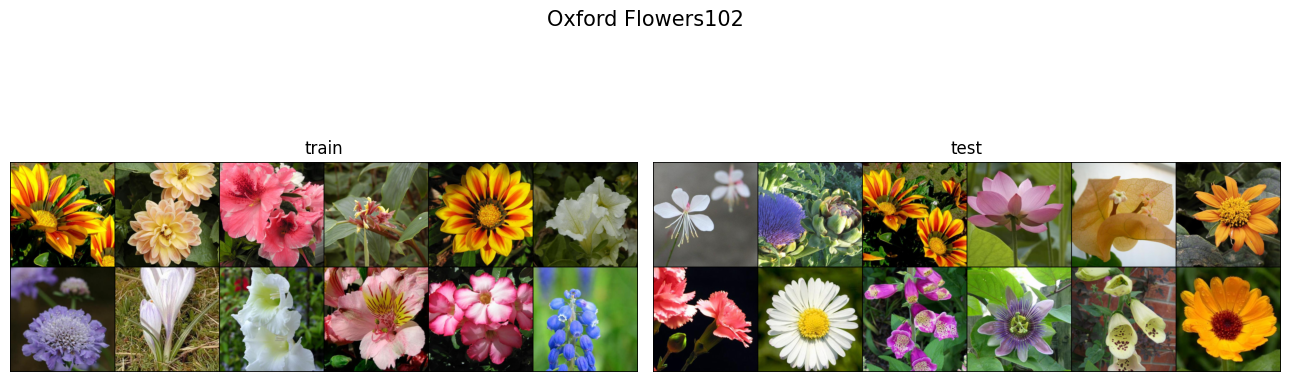

FFHQ-128 Faces
  train shape     : (12, 3, 256, 256)
  reference shape : (12, 3, 256, 256)
  train source    : ffhq128:all
  reference source: ffhq128:all
  train labels    : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  validation      : {'train_source_id': 'ffhq128:all', 'reference_source_id': 'ffhq128:all', 'train_role': 'train', 'reference_role': 'same_corpus_holdout', 'same_source': True, 'same_source_allowed': True, 'overlap_checked': True, 'overlap_count': 0}



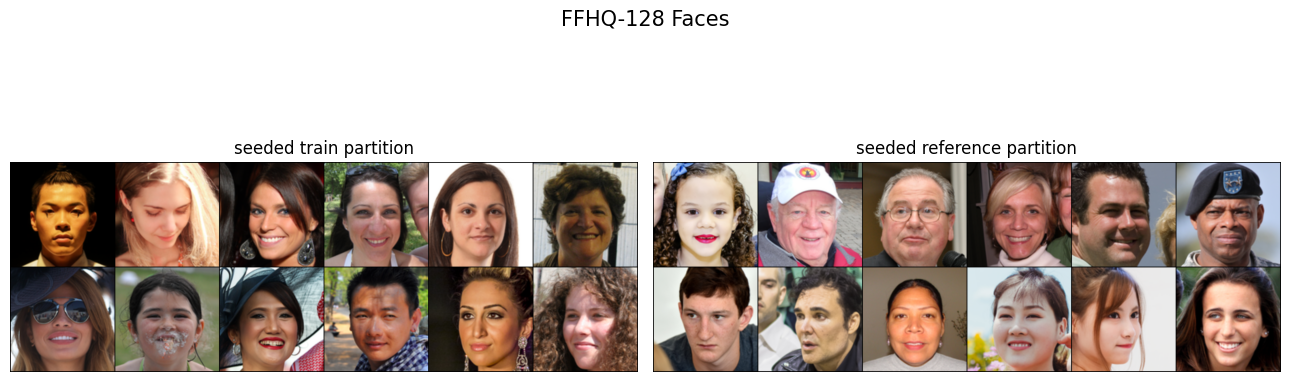

In [7]:
bundles = {}

for spec in DATASETS:
    config = build_gallery_config(spec)
    bundle = build_data_bundle(config)
    bundles[spec["dataset"]] = bundle
    summarize_bundle(spec, bundle)
    plot_train_reference(spec, bundle)

Notes:

- Flowers102, CelebA, and AFHQ-v2 use their explicit train/test-style splits here.
- FFHQ does not ship with an official train/test split in this staged format, so the loader displays a seeded train partition and a disjoint seeded reference partition from the same 70k-image corpus.